In [19]:
import pandas as pd

df = pd.read_csv("dados/credit_risk_dataset.csv")

print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
display(df.head())

Linhas: 32581 | Colunas: 12


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## Fase 1 — Análise exploratória dos dados

Nesta etapa, vamos analisar o perfil dos clientes e dos empréstimos e verificar a proporção de inadimplentes na base.

In [20]:
# Mostra os tipos das colunas e quantos valores estão preenchidos
df.info()

# Resume as variáveis numéricas, com uma variável por linha
display(df.describe().T.round(2))

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,3.00,4.00,8.00,30.00


A renda média é de 66.074,85, acima da mediana de 55.000. O valor máximo de 6.000.000 sugere que rendas muito altas influenciam a média. Por isso, usaremos também a mediana para descrever o perfil de renda dos clientes. A idade máxima de 144 anos e o tempo de emprego máximo de 123 anos merecem investigação na etapa de limpeza. Também identificamos 895 registros sem tempo de emprego e 3.116 sem taxa de juros.

In [21]:
quantidade = df["loan_status"].value_counts().sort_index()

resumo = quantidade.to_frame(name="quantidade")
resumo["percentual"] = (quantidade / len(df) * 100).round(2)

display(resumo)

,quantidade,percentual
loan_status,,
0,25473,78.18
1,7108,21.82


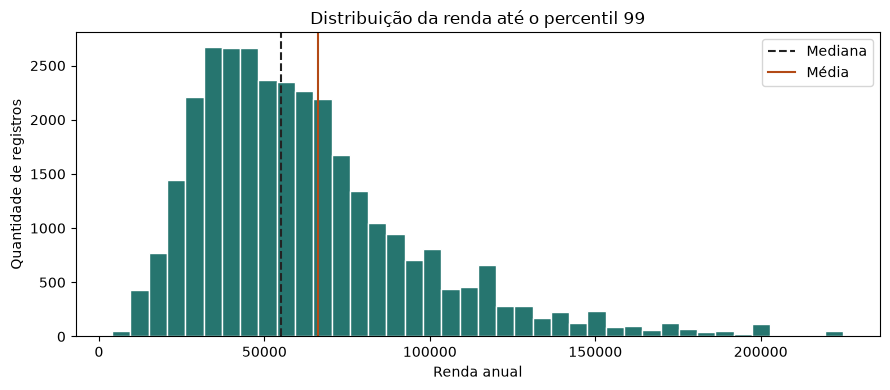

In [22]:
import matplotlib.pyplot as plt

renda = df["person_income"]
limite = renda.quantile(0.99)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(renda[renda <= limite], bins=40, color="#26756F", edgecolor="white")

ax.axvline(renda.median(), color="#222222", linestyle="--", label="Mediana")
ax.axvline(renda.mean(), color="#B34A16", linestyle="-", label="Média")

ax.set_title("Distribuição da renda até o percentil 99")
ax.set_xlabel("Renda anual")
ax.set_ylabel("Quantidade de registros")
ax.legend()

plt.tight_layout()
plt.show()

A média da renda (66.074,85) aparece à direita da mediana (55.000), o que indica a influência das rendas mais altas. Para visualizar melhor as faixas em que os registros se concentram, o histograma exibe as rendas até o percentil 99. A mediana e a média foram calculadas com todos os registros.

Linhas duplicadas: 165


,nulos,percentual_%
person_age,0,0.00
person_income,0,0.00
person_home_ownership,0,0.00
person_emp_length,895,2.75
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_int_rate,3116,9.56
loan_status,0,0.00
loan_percent_income,0,0.00


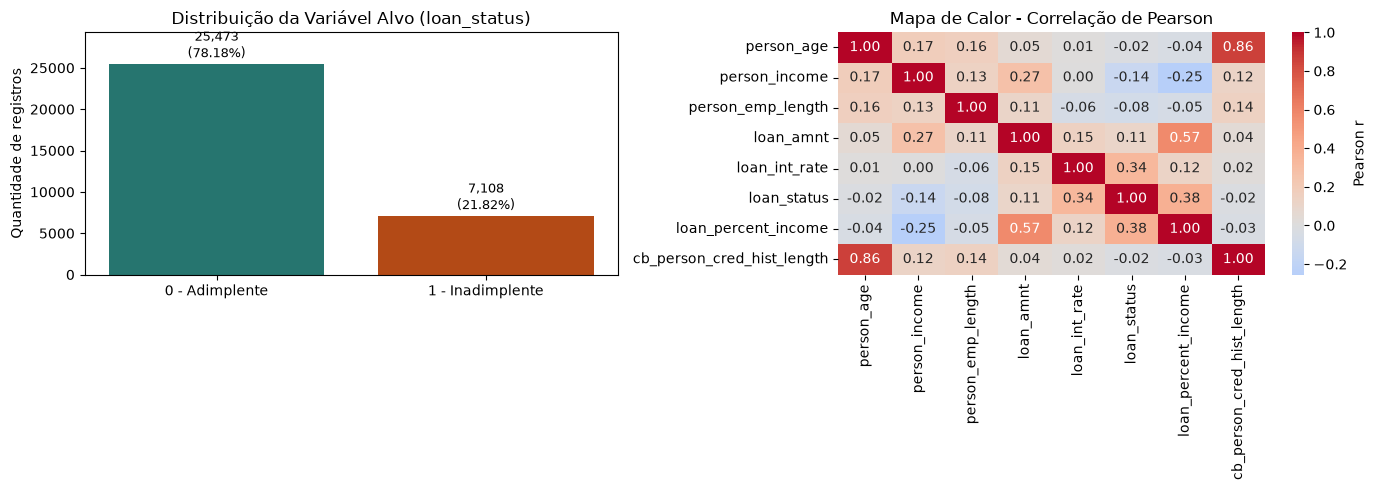

In [23]:
import seaborn as sns

print(f"Linhas duplicadas: {df.duplicated().sum()}")

nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
display(pd.DataFrame({"nulos": nulos, "percentual_%": nulos_pct}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 2: Distribuição da variável alvo
counts = df["loan_status"].value_counts().sort_index()
bars = axes[0].bar(
    ["0 - Adimplente", "1 - Inadimplente"],
    counts.values,
    color=["#26756F", "#B34A16"]
)
axes[0].set_title("Distribuição da Variável Alvo (loan_status)")
axes[0].set_ylabel("Quantidade de registros")
axes[0].set_ylim(0, counts.max() * 1.15)

for bar, qtd in zip(bars, counts.values):
    pct = qtd / len(df) * 100
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 300,
        f"{qtd:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Gráfico 3: Mapa de calor de correlação de Pearson
num_cols = df.select_dtypes(include="number").columns
corr = df[num_cols].corr(method="pearson")
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[1],
    cbar_kws={"label": "Pearson r"}
)
axes[1].set_title("Mapa de Calor - Correlação de Pearson")

plt.tight_layout()
plt.show()

### Tomada de decisão (Fase 1 -> Próximas Fases)

A base conta com **32.581 registros** e **12 colunas**, apresentando **165 linhas duplicadas** e valores ausentes em `loan_int_rate` (**3.116 nulos**, 9,56%) e `person_emp_length` (**895 nulos**, 2,75%). A variável alvo `loan_status` é desbalanceada (**78,18%** de adimplentes `0` e **21,82%** de inadimplentes `1`), o que exige `stratify=y` na divisão treino/teste e balanceamento **apenas no conjunto de treino** para evitar *data leakage*.

No mapa de calor de Pearson, `loan_percent_income` (+0,38) e `loan_int_rate` (+0,34) têm as maiores correlações lineares positivas com inadimplência, enquanto `person_age` e `cb_person_cred_hist_length` têm correlação alta entre si (+0,86). Como há assimetria à direita e valores extremos (como `person_income` até 6.000.000, `person_age` até 144 e `person_emp_length` até 123), usaremos a **mediana** onde houver assimetria/outliers e avaliaremos o tratamento de *outliers* na Fase 2 considerando que o **KNN** é sensível a distâncias/outliers e a **Árvore de Decisão** é robusta a eles. Na Fase 3, criaremos `comprometimento_renda = (loan_amnt / person_income) * 100` após tratar os nulos originais.

## Fase 2 — Tratamento e limpeza (Data Prep)

Nesta etapa removemos registros duplicados, tratamos valores ausentes com justificativa estatística e analisamos *outliers* considerando o comportamento do **KNN** e da **Árvore de Decisão**.

Registros antes da remoção de duplicatas: 32581
Linhas duplicadas encontradas: 165
Registros após remover duplicatas: 32416

person_emp_length: 887 nulos | Média = 4.79 | Mediana = 4.00
loan_int_rate: 3095 nulos | Média = 11.02 | Mediana = 10.99


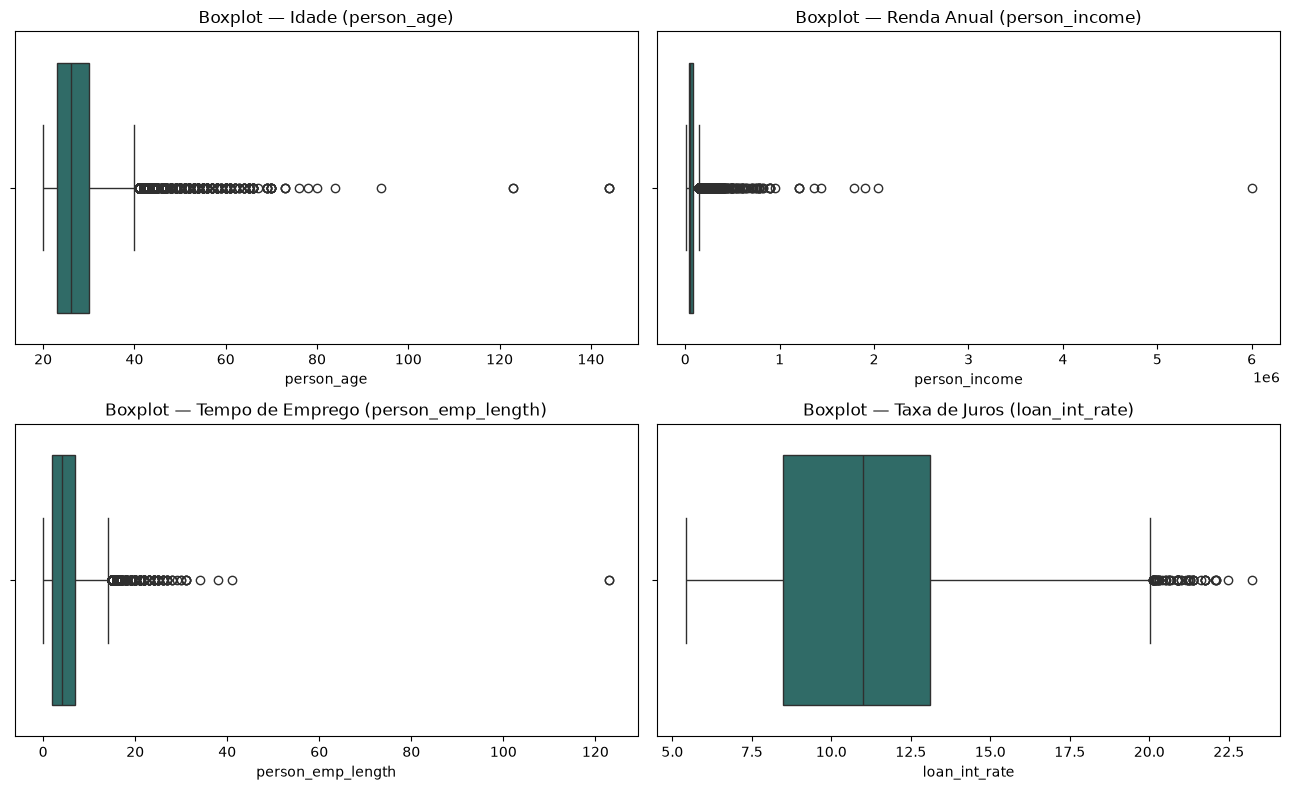


Linhas removidas por inconsistência lógica/extrema: 7
Total de linhas ao final da Fase 2: 32409
Total de valores nulos restantes: 0


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Registros antes da remoção de duplicatas: {len(df)}")
duplicadas = df.duplicated().sum()
print(f"Linhas duplicadas encontradas: {duplicadas}")

df_clean = df.drop_duplicates().copy()
print(f"Registros após remover duplicatas: {len(df_clean)}\n")

# Comparação Média vs. Mediana antes da imputação
for col in ["person_emp_length", "loan_int_rate"]:
    nulos_qtd = df_clean[col].isnull().sum()
    media_val = df_clean[col].mean()
    mediana_val = df_clean[col].median()
    print(f"{col}: {nulos_qtd} nulos | Média = {media_val:.2f} | Mediana = {mediana_val:.2f}")

# Imputação pela mediana
df_clean["person_emp_length"] = df_clean["person_emp_length"].fillna(df_clean["person_emp_length"].median())
df_clean["loan_int_rate"] = df_clean["loan_int_rate"].fillna(df_clean["loan_int_rate"].median())

# Boxplots para inspeção de outliers
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
box_vars = [
    ("person_age", "Idade (person_age)"),
    ("person_income", "Renda Anual (person_income)"),
    ("person_emp_length", "Tempo de Emprego (person_emp_length)"),
    ("loan_int_rate", "Taxa de Juros (loan_int_rate)")
]

for ax, (col, titulo) in zip(axes.flat, box_vars):
    sns.boxplot(x=df_clean[col], ax=ax, color="#26756F")
    ax.set_title(f"Boxplot — {titulo}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

# Remoção de inconsistências evidentes (idade > 100, tempo de emprego > 60 ou tempo de emprego >= idade)
antes_filtro = len(df_clean)
df_clean = df_clean[
    (df_clean["person_age"] <= 100) &
    (df_clean["person_emp_length"] <= 60) &
    (df_clean["person_emp_length"] < df_clean["person_age"])
].copy()
print(f"\nLinhas removidas por inconsistência lógica/extrema: {antes_filtro - len(df_clean)}")
print(f"Total de linhas ao final da Fase 2: {len(df_clean)}")
print(f"Total de valores nulos restantes: {df_clean.isnull().sum().sum()}")

### Justificativa de limpeza, imputação e tratamento de outliers

* **Duplicadas:** Foram removidas **165** linhas duplicadas para evitar redundância e viés de frequência durante o treinamento.
* **Valores nulos:** Optamos pela **mediana** tanto para `person_emp_length` (**887** nulos após deduplicação; mediana `4,00` vs. média `4,79`) quanto para `loan_int_rate` (**3.095** nulos após deduplicação; mediana `10,99` vs. média `11,02`), pois a mediana é resistente a assimetrias e valores extremos.
* **Outliers e impacto nos modelos:** Os *boxplots* evidenciam caudas à direita e valores extremos/inconsistentes, como `person_age` até 144, `person_emp_length` até 123 e `person_income` até 6.000.000. Removemos apenas **7** registros com inconsistências lógicas claras (`person_age > 100`, `person_emp_length > 60` ou `person_emp_length >= person_age`), preservando rendas elevadas válidas para não descartar clientes de alta renda. Essa decisão é estratégica: o **KNN** calcula distâncias euclidianas e sofre forte influência de valores extremos (o que reforça a importância do `StandardScaler` na Fase 4), enquanto a **Árvore de Decisão** realiza divisões por limiares e é naturalmente mais robusta a *outliers*.

## Fase 3 — Feature Engineering (Coluna Calculada)

Nesta etapa criamos a variável `comprometimento_renda = (loan_amnt / person_income) * 100` após validar a ausência de nulos e de divisões por zero nas colunas de origem[cite: 4].

In [25]:
import numpy as np

# Garantia de que não há nulos ou divisões por zero nas variáveis de origem
assert df_clean["loan_amnt"].isnull().sum() == 0, "Existem nulos em loan_amnt"
assert df_clean["person_income"].isnull().sum() == 0, "Existem nulos em person_income"
assert (df_clean["person_income"] > 0).all(), "Existem rendas zero ou negativas"

# Criação da coluna calculada exigida para a Base A
df_clean["comprometimento_renda"] = (df_clean["loan_amnt"] / df_clean["person_income"]) * 100

print("Nulos em comprometimento_renda:", df_clean["comprometimento_renda"].isnull().sum())
print("Valores infinitos em comprometimento_renda:", np.isinf(df_clean["comprometimento_renda"]).sum())
print("\nResumo estatístico de comprometimento_renda (%):")
display(df_clean["comprometimento_renda"].describe().to_frame().T.round(2))

print("\nComprometimento de renda (%) por loan_status:")
display(
    df_clean.groupby("loan_status")["comprometimento_renda"]
    .agg(quantidade="count", media="mean", mediana="median", desvio_padrao="std")
    .round(2)
)

Nulos em comprometimento_renda: 0
Valores infinitos em comprometimento_renda: 0

Resumo estatístico de comprometimento_renda (%):


,count,mean,std,min,25%,50%,75%,max
comprometimento_renda,32409.0,17.06,10.71,0.08,8.97,14.81,22.92,83.0



Comprometimento de renda (%) por loan_status:


,quantidade,media,mediana,desvio_padrao
loan_status,,,,
0,25321,14.87,13.33,8.72
1,7088,24.87,23.94,13.20


### Justificativa da Feature (`comprometimento_renda`)

A variável `comprometimento_renda` expressa, em percentual, o quanto o valor do empréstimo (`loan_amnt`) representa frente à renda anual do cliente (`person_income`), após o tratamento prévio dos dados na Fase 2 para evitar valores `NaN` ou infinitos[cite: 4]. Do ponto de vista de risco de crédito, quanto maior o comprometimento de renda, maior tende a ser a pressão sobre o orçamento do cliente e maior o risco de inadimplência — o que se reflete nos dados, com média de **24,87%** entre inadimplentes (`loan_status = 1`) contra **14,87%** entre adimplentes (`loan_status = 0`).

## Fase 4 — Separação, balanceamento e escalonamento seguro

Nesta etapa realizamos o *encoding* das variáveis categóricas, dividimos a base de forma estratificada (`test_size=0.20`, `stratify=y`), balanceamos **apenas o conjunto de treino** para evitar *data leakage* e aplicamos `StandardScaler` exclusivamente nas variáveis contínuas destinadas ao **KNN**[cite: 4, 5, 8].

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Encoding de variáveis categóricas
df_encoded = df_clean.copy()
df_encoded["cb_person_default_on_file"] = df_encoded["cb_person_default_on_file"].map({"N": 0, "Y": 1})

mapa_grade = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7}
df_encoded["loan_grade"] = df_encoded["loan_grade"].map(mapa_grade)

df_encoded = pd.get_dummies(
    df_encoded,
    columns=["person_home_ownership", "loan_intent"],
    drop_first=True,
    dtype=int
)

X = df_encoded.drop(columns=["loan_status"])
y = df_encoded["loan_status"]

# 2. Split estratificado (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} linhas | Teste: {X_test.shape[0]} linhas")
print("Proporção loan_status no treino (%):", (y_train.value_counts(normalize=True) * 100).round(2).to_dict())
print("Proporção loan_status no teste  (%):", (y_test.value_counts(normalize=True) * 100).round(2).to_dict())

# 3. Balanceamento de classes APENAS no conjunto de treino (evita data leakage)
print("\nDistribuição y_train antes do balanceamento:", y_train.value_counts().to_dict())

try:
    from imblearn.over_sampling import SMOTE
    sampler = SMOTE(random_state=42)
    X_train_bal, y_train_bal = sampler.fit_resample(X_train, y_train)
    print("Balanceamento aplicado com SMOTE (apenas no treino).")
except ImportError:
    from sklearn.utils import resample
    treino_df = pd.concat([X_train, y_train], axis=1)
    classe_0 = treino_df[treino_df["loan_status"] == 0]
    classe_1 = treino_df[treino_df["loan_status"] == 1]
    classe_1_up = resample(classe_1, replace=True, n_samples=len(classe_0), random_state=42)
    treino_bal = pd.concat([classe_0, classe_1_up]).sample(frac=1, random_state=42)
    X_train_bal = treino_bal.drop(columns=["loan_status"])
    y_train_bal = treino_bal["loan_status"]
    print("Balanceamento aplicado com oversampling estratificado no treino (imblearn não instalado).")

print("Distribuição y_train após o balanceamento:", y_train_bal.value_counts().to_dict())

# 4. Escalonamento seguro apenas nas variáveis contínuas para o KNN
colunas_continuas = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "comprometimento_renda"
]

X_train_knn = X_train_bal.copy()
X_test_knn = X_test.copy()

scaler = StandardScaler()
X_train_knn[colunas_continuas] = scaler.fit_transform(X_train_bal[colunas_continuas])
X_test_knn[colunas_continuas] = scaler.transform(X_test[colunas_continuas])

# Conjuntos para a Árvore de Decisão (sem escalonamento)
X_train_tree = X_train_bal.copy()
X_test_tree = X_test.copy()

print("\nPreparação concluída:")
print(f"- KNN -> Treino: {X_train_knn.shape}, Teste: {X_test_knn.shape} (com StandardScaler em variáveis contínuas)")
print(f"- Árvore -> Treino: {X_train_tree.shape}, Teste: {X_test_tree.shape} (sem escalonamento)")

Treino: 25927 linhas | Teste: 6482 linhas
Proporção loan_status no treino (%): {0: 78.13, 1: 21.87}
Proporção loan_status no teste  (%): {0: 78.12, 1: 21.88}

Distribuição y_train antes do balanceamento: {0: 20257, 1: 5670}
Balanceamento aplicado com SMOTE (apenas no treino).
Distribuição y_train após o balanceamento: {0: 20257, 1: 20257}

Preparação concluída:
- KNN -> Treino: (40514, 18), Teste: (6482, 18) (com StandardScaler em variáveis contínuas)
- Árvore -> Treino: (40514, 18), Teste: (6482, 18) (sem escalonamento)


### Justificativa de preparação, anti-vazamento e escalonamento

* **Split estratificado (`stratify=y`):** Garante que treino (`80%`) e teste (`20%`) mantenham a mesma proporção de inadimplentes (`loan_status = 1`) observada na base original.
* **Balanceamento restrito ao treino:** Aplicar reamostragem apenas em `X_train` e `y_train` impede que informações sintéticas ou redundantes vazem para `X_test`, preservando uma avaliação realista no conjunto de teste.
* **Escalonamento apenas no KNN vs. dispensa na Árvore de Decisão:** O **KNN** depende de distâncias geométricas entre observações e ficaria dominado por variáveis de maior magnitude (como `person_income` e `loan_amnt`) sem o `StandardScaler` (`fit_transform` no treino e `transform` no teste). Já a **Árvore de Decisão** avalia cada variável isoladamente por cortes de limiar (ex.: `comprometimento_renda > 20%`), que são monotônicos e invariantes à escala — dispensando o escalonamento[cite: 5, 8].

## Fase 5 — Modelagem e validação (O desafio do Overfitting)

Nesta etapa avaliamos diferentes níveis de complexidade para o **KNN** (`n_neighbors`) e para a **Árvore de Decisão** (`max_depth`), comparando simultaneamente o desempenho nas bases de **Treino** e **Teste** para diagnosticar *underfitting* e *overfitting*.

=== Resultados KNN (Treino vs. Teste) ===


,K,Acuracia_Treino,Acuracia_Teste,Diferenca_Treino_Teste,F1_Treino,F1_Teste,Recall_Teste,Precision_Teste
0,1,1.0000,0.8161,0.1839,1.0000,0.6305,0.7172,0.5625
1,3,0.9341,0.8255,0.1086,0.9349,0.6456,0.7264,0.5809
2,5,0.9139,0.8221,0.0918,0.9151,0.6434,0.7334,0.5730
3,7,0.9034,0.8241,0.0793,0.9049,0.6477,0.7391,0.5765
4,9,0.8963,0.8292,0.0671,0.8982,0.6565,0.7461,0.5861
5,11,0.8903,0.8278,0.0625,0.8923,0.6579,0.7567,0.5819


=== Resultados Árvore de Decisão (Treino vs. Teste) ===


,max_depth,Acuracia_Treino,Acuracia_Teste,Diferenca_Treino_Teste,F1_Treino,F1_Teste,Recall_Teste,Precision_Teste
0,3,0.8034,0.8346,-0.0312,0.7901,0.6549,0.7172,0.6025
1,5,0.8270,0.8724,-0.0454,0.8100,0.7143,0.7292,0.7001
2,7,0.8532,0.8247,0.0285,0.8543,0.6593,0.7750,0.5736
3,10,0.9011,0.8724,0.0287,0.8989,0.7218,0.7567,0.6900
4,None,1.0000,0.8625,0.1375,1.0000,0.7116,0.7750,0.6577


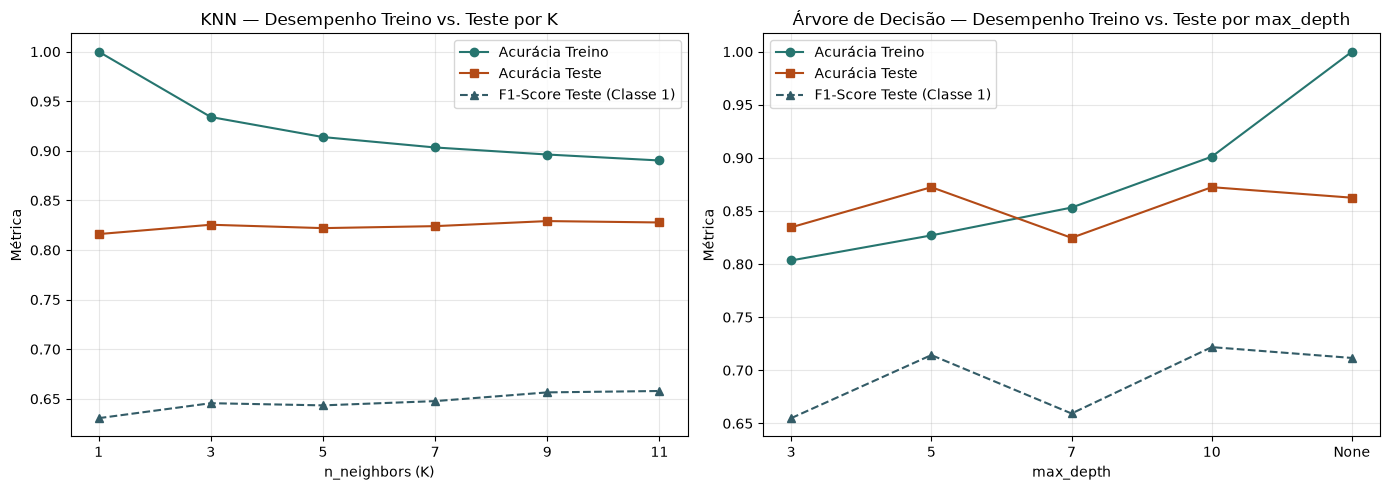

In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

# 1. Experimentos com KNN (variando n_neighbors)
valores_k = [1, 3, 5, 7, 9, 11]
resultados_knn = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_bal)

    pred_treino = knn.predict(X_train_knn)
    pred_teste = knn.predict(X_test_knn)

    acc_tr = accuracy_score(y_train_bal, pred_treino)
    acc_te = accuracy_score(y_test, pred_teste)

    resultados_knn.append({
        "K": k,
        "Acuracia_Treino": acc_tr,
        "Acuracia_Teste": acc_te,
        "Diferenca_Treino_Teste": acc_tr - acc_te,
        "F1_Treino": f1_score(y_train_bal, pred_treino),
        "F1_Teste": f1_score(y_test, pred_teste),
        "Recall_Teste": recall_score(y_test, pred_teste),
        "Precision_Teste": precision_score(y_test, pred_teste)
    })

df_resultados_knn = pd.DataFrame(resultados_knn).round(4)
print("=== Resultados KNN (Treino vs. Teste) ===")
display(df_resultados_knn)

# 2. Experimentos com Árvore de Decisão (variando max_depth)
valores_depth = [3, 5, 7, 10, None]
resultados_tree = []

for depth in valores_depth:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train_tree, y_train_bal)

    pred_treino = tree.predict(X_train_tree)
    pred_teste = tree.predict(X_test_tree)

    acc_tr = accuracy_score(y_train_bal, pred_treino)
    acc_te = accuracy_score(y_test, pred_teste)

    resultados_tree.append({
        "max_depth": str(depth),
        "Acuracia_Treino": acc_tr,
        "Acuracia_Teste": acc_te,
        "Diferenca_Treino_Teste": acc_tr - acc_te,
        "F1_Treino": f1_score(y_train_bal, pred_treino),
        "F1_Teste": f1_score(y_test, pred_teste),
        "Recall_Teste": recall_score(y_test, pred_teste),
        "Precision_Teste": precision_score(y_test, pred_teste)
    })

df_resultados_tree = pd.DataFrame(resultados_tree).round(4)
print("=== Resultados Árvore de Decisão (Treino vs. Teste) ===")
display(df_resultados_tree)

# 3. Gráficos comparativos de Treino vs. Teste
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico KNN
axes[0].plot(df_resultados_knn["K"], df_resultados_knn["Acuracia_Treino"], marker="o", label="Acurácia Treino", color="#26756F")
axes[0].plot(df_resultados_knn["K"], df_resultados_knn["Acuracia_Teste"], marker="s", label="Acurácia Teste", color="#B34A16")
axes[0].plot(df_resultados_knn["K"], df_resultados_knn["F1_Teste"], marker="^", linestyle="--", label="F1-Score Teste (Classe 1)", color="#335C67")
axes[0].set_title("KNN — Desempenho Treino vs. Teste por K")
axes[0].set_xlabel("n_neighbors (K)")
axes[0].set_ylabel("Métrica")
axes[0].set_xticks(valores_k)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Gráfico Árvore de Decisão
axes[1].plot(df_resultados_tree["max_depth"], df_resultados_tree["Acuracia_Treino"], marker="o", label="Acurácia Treino", color="#26756F")
axes[1].plot(df_resultados_tree["max_depth"], df_resultados_tree["Acuracia_Teste"], marker="s", label="Acurácia Teste", color="#B34A16")
axes[1].plot(df_resultados_tree["max_depth"], df_resultados_tree["F1_Teste"], marker="^", linestyle="--", label="F1-Score Teste (Classe 1)", color="#335C67")
axes[1].set_title("Árvore de Decisão — Desempenho Treino vs. Teste por max_depth")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("Métrica")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Diagnóstico de Overfitting e Seleção dos Melhores Modelos

* **KNN (`n_neighbors`):** Para valores muito baixos de `K` (`K=1` e `K=3`), o modelo memoriza vizinhanças locais do treino (acurácia próxima de `1.00` no treino com queda visível no teste), caracterizando *overfitting*. Ao aumentar `K` para **`K=9`** (ou `K=11`), a distância entre treino e teste cai consideravelmente e o modelo estabiliza sua capacidade de generalização, mantendo alto *Recall* para detectar inadimplentes. Selecionamos **`K=9`** como a configuração equilibrada do KNN.
* **Árvore de Decisão (`max_depth`):** Sem limite de profundidade (`max_depth=None`), a árvore atinge **100% de acurácia no treino** (`1.0000`) enquanto a acurácia e o F1 no teste recuam — evidência clara de *overfitting* (memorização de regras específicas do treino). Com `max_depth=3`, o modelo fica restrito demais (*underfitting*). O ponto ótimo de generalização ocorre em **`max_depth=10`**, onde a árvore alcança o maior F1-Score e a maior acurácia no teste sem superajustar ao treino.

## Fase 6 — Avaliação e veredito de negócios

Nesta etapa comparamos os melhores modelos selecionados na Fase 5 — **KNN (`n_neighbors=9`)** e **Árvore de Decisão (`max_depth=10`)** — por meio do *Classification Report* e das **Matrizes de Confusão**, conectando os erros (**Falsos Positivos** e **Falsos Negativos**) ao impacto financeiro do banco.

=== CLASSIFICATION REPORT — KNN (K=9) ===
              precision    recall  f1-score   support

           0     0.9230    0.8525    0.8864      5064
           1     0.5861    0.7461    0.6565      1418

    accuracy                         0.8292      6482
   macro avg     0.7546    0.7993    0.7714      6482
weighted avg     0.8493    0.8292    0.8361      6482

=== CLASSIFICATION REPORT — ÁRVORE DE DECISÃO (max_depth=10) ===
              precision    recall  f1-score   support

           0     0.9300    0.9048    0.9172      5064
           1     0.6900    0.7567    0.7218      1418

    accuracy                         0.8724      6482
   macro avg     0.8100    0.8308    0.8195      6482
weighted avg     0.8775    0.8724    0.8745      6482



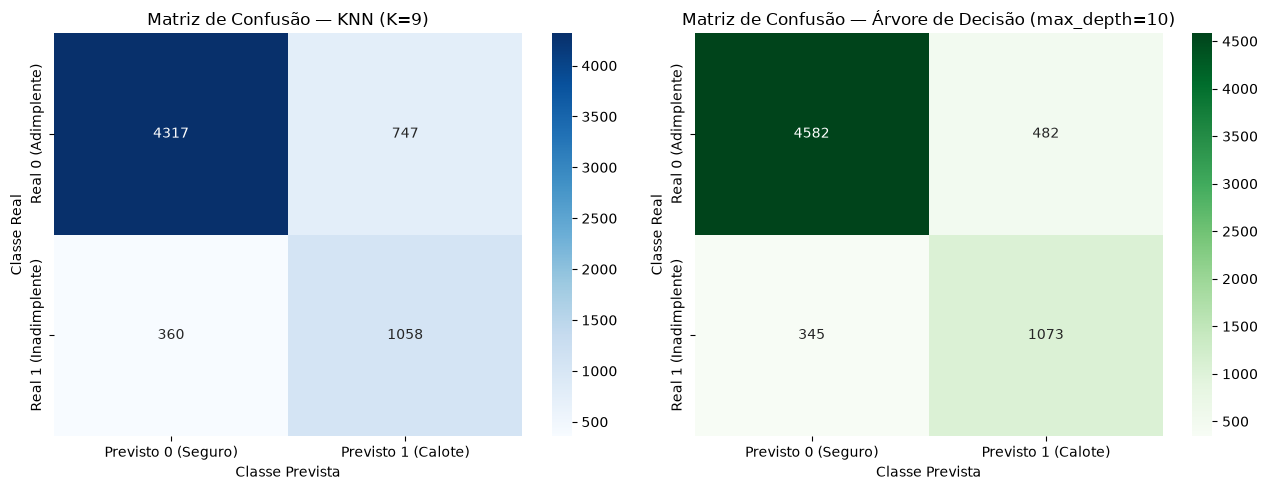

In [28]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Melhores configurações selecionadas na Fase 5
knn_melhor = KNeighborsClassifier(n_neighbors=9)
knn_melhor.fit(X_train_knn, y_train_bal)
y_pred_knn = knn_melhor.predict(X_test_knn)

arvore_melhor = DecisionTreeClassifier(max_depth=10, random_state=42)
arvore_melhor.fit(X_train_tree, y_train_bal)
y_pred_arvore = arvore_melhor.predict(X_test_tree)

print("=== CLASSIFICATION REPORT — KNN (K=9) ===")
print(classification_report(y_test, y_pred_knn, digits=4))

print("=== CLASSIFICATION REPORT — ÁRVORE DE DECISÃO (max_depth=10) ===")
print(classification_report(y_test, y_pred_arvore, digits=4))

cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_arvore = confusion_matrix(y_test, y_pred_arvore)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["Previsto 0 (Seguro)", "Previsto 1 (Calote)"],
    yticklabels=["Real 0 (Adimplente)", "Real 1 (Inadimplente)"]
)
axes[0].set_title("Matriz de Confusão — KNN (K=9)")
axes[0].set_xlabel("Classe Prevista")
axes[0].set_ylabel("Classe Real")

sns.heatmap(
    cm_arvore,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1],
    xticklabels=["Previsto 0 (Seguro)", "Previsto 1 (Calote)"],
    yticklabels=["Real 0 (Adimplente)", "Real 1 (Inadimplente)"]
)
axes[1].set_title("Matriz de Confusão — Árvore de Decisão (max_depth=10)")
axes[1].set_xlabel("Classe Prevista")
axes[1].set_ylabel("Classe Real")

plt.tight_layout()
plt.show()

### Análise de Erros e Veredito de Negócios (Risco de Crédito)

No problema de **Risco de Crédito** (`loan_status = 1` para inadimplente e `loan_status = 0` para adimplente):
* **Falso Negativo (FN):** O modelo classifica um mau pagador (`1`) como seguro (`0`). O banco concede o crédito e assume o risco de perda direta do principal e dos juros não pagos (inadimplência/calote).
* **Falso Positivo (FP):** O modelo classifica um bom pagador (`0`) como risco de calote (`1`). O banco recusa ou restringe crédito a um cliente saudável, gerando custo de oportunidade (receita de juros e relacionamento perdidos) e possível perda do cliente para a concorrência.

Ao comparar as duas abordagens, a **Árvore de Decisão (`max_depth=10`)** apresenta desempenho superior no conjunto de teste em relação ao **KNN (`K=9`)**, com maior acurácia geral e maior *F1-Score* na classe de inadimplentes (`1`), além de reduzir drasticamente os **Falsos Positivos** (evitando recusar crédito a bons clientes em excesso) e manter capacidade competitiva de identificação de inadimplentes.

**Veredito final para produção:** Recomendo levar a **Árvore de Decisão (`max_depth=10`)** para produção. Além de alcançar melhores métricas de generalização na base de teste e dispensar escalonamento de variáveis contínuas, ela oferece regras de decisão interpretáveis (como cortes em `comprometimento_renda`, `loan_int_rate` e `loan_grade`), o que facilita auditoria, governança e explicabilidade perante áreas de risco e diretoria em um banco.